# 🐅 Tiger Segmentation & Canonical Texture Template Extraction Demo

This notebook demonstrates using the trained **YOLOv8n-seg** model (`trained_models/tiger_segmenter_best.pt`) on any camera image, isolating the foreground tiger, **unpacking visible markings into the canonical 3D UV texture template layout** (`generated_textures` adhering), and **threshold-gated multi-angle stitching for individual re-identification**.

### Pipeline Overview:
1. **Load Trained Model**: Loads the weights trained with GPU acceleration.
2. **Single Image Inference**: Predicts the bounding box, class confidence, and polygon segmentation mask.
3. **Mask Extraction**: Generates binary masks and transparent overlays.
4. **Foliage Removal / Cutout**: Isolates the tiger with background zeroed out.
5. **Visual Dashboard**: Displays side-by-side comparison of original, mask, overlay, and cutout.
6. **Cropped Tiger Patch**: Tight foreground bounding crop isolating the animal.
7. **Stripe Marking Extraction**: Isolates dark melanin stripe ridges using morphological black-hat filtering & adaptive contrast thresholding.
8. **Canonical UV Texture Template Unpacking**: Unpacks the visible tiger surface directly into the 2048x2048 canonical UV texture atlas. Missing limbs or occluded regions (e.g. tree trunks, unobserved angles) remain strictly blank (pure white [255, 255, 255]). Zero default skin or synthetic data is substituted.
9. **Threshold-Gated Multi-Angle Stitching (Individuality Re-ID)**: Evaluates stripe texture intersection across multiple camera angles. Only when intersection similarity exceeds the trained threshold (>= 0.70) are views recognized as the same individual tiger and stitched together; otherwise, they remain separate and incomplete.
10. **Input Image vs. Final Stitched Template**: Side-by-side comparison of the raw uploaded camera photo against the resulting unpacked/stitched canonical individuality template.

In [12]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

# Check device capabilities
print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU      : {torch.cuda.get_device_name(0)}")

PyTorch Version : 2.14.1+cu132
CUDA Available  : True
Active GPU      : NVIDIA GeForce RTX 5050 Laptop GPU


## 1. Configure Model & Target Image
Specify the target image you want to segment. You can replace `IMAGE_PATH` with any image.

In [ ]:
# Path to the trained segmentation model
MODEL_PATH = "trained_models/tiger_segmenter_best.pt"

# Path to target image:
# Set to an image with matching 3D basecolor/mesh tracking (e.g. 000001.png):
IMAGE_PATH = "Marking extraction/dataset/images/000001.png"

assert os.path.exists(MODEL_PATH), f"Model weights not found at: {MODEL_PATH}"
assert os.path.exists(IMAGE_PATH), f"Target image not found at: {IMAGE_PATH}"

print(f"Target Image: {IMAGE_PATH}")
print(f"Model Path  : {MODEL_PATH}")

Target Image: Marking extraction/dataset/images/000001.png
Model Path  : trained_models/tiger_segmenter_best.pt


## 2. Load Model & Run Segmentation Inference

In [14]:
# Load trained model
model = YOLO(MODEL_PATH)

# Read image in RGB
orig_bgr = cv2.imread(IMAGE_PATH)
orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
h, w = orig_rgb.shape[:2]

# Run inference
results = model.predict(source=orig_bgr, conf=0.25, verbose=False)
res = results[0]

num_detected = len(res.boxes) if res.boxes is not None else 0
print(f"Image Dimensions : {w} x {h}")
print(f"Tigers Detected  : {num_detected}")

if num_detected > 0:
    for i, box in enumerate(res.boxes):
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
        conf = float(box.conf[0])
        print(f"  Detection #{i+1}: Confidence={conf:.1%}, BBox=({x1}, {y1}, {x2}, {y2})")

Image Dimensions : 1920 x 1080
Tigers Detected  : 2
  Detection #1: Confidence=79.2%, BBox=(864, 259, 1397, 693)
  Detection #2: Confidence=40.6%, BBox=(652, 249, 1241, 623)


## 3. Extract Segmentation Polygon & Binary Mask

In [15]:
# Create binary mask from predicted polygon contours
mask_bin = np.zeros((h, w), dtype=np.uint8)

if res.masks is not None and len(res.masks) > 0:
    for poly in res.masks.xy:
        if len(poly) > 0:
            cv2.fillPoly(mask_bin, [np.int32(poly)], 255)

mask_bool = mask_bin > 0
tiger_pixel_count = int(np.sum(mask_bool))
print(f"Tiger Mask Pixels : {tiger_pixel_count:,} ({tiger_pixel_count / (w * h) * 100:.2f}% of image)")

# 1. Create transparent color overlay (cyan mask over raw image)
overlay = orig_rgb.copy()
overlay[mask_bool] = (0.55 * overlay[mask_bool] + 0.45 * np.array([0, 240, 160])).astype(np.uint8)

# 2. Create isolated tiger cutout with background zeroed out
cutout = np.zeros_like(orig_rgb)
cutout[mask_bool] = orig_rgb[mask_bool]

# 3. Compute tight bounding crop
if np.any(mask_bool):
    ys, xs = np.nonzero(mask_bool)
    pad = 16
    ymin, ymax = max(0, ys.min() - pad), min(h - 1, ys.max() + pad)
    xmin, xmax = max(0, xs.min() - pad), min(w - 1, xs.max() + pad)
    tight_patch = orig_rgb[ymin:ymax + 1, xmin:xmax + 1]
    tight_mask = mask_bool[ymin:ymax + 1, xmin:xmax + 1]
else:
    tight_patch = orig_rgb
    tight_mask = np.ones((h, w), dtype=bool)

Tiger Mask Pixels : 161,752 (7.80% of image)


## 4. Visual Dashboard: Original, Overlay, Binary Mask, and Cutout

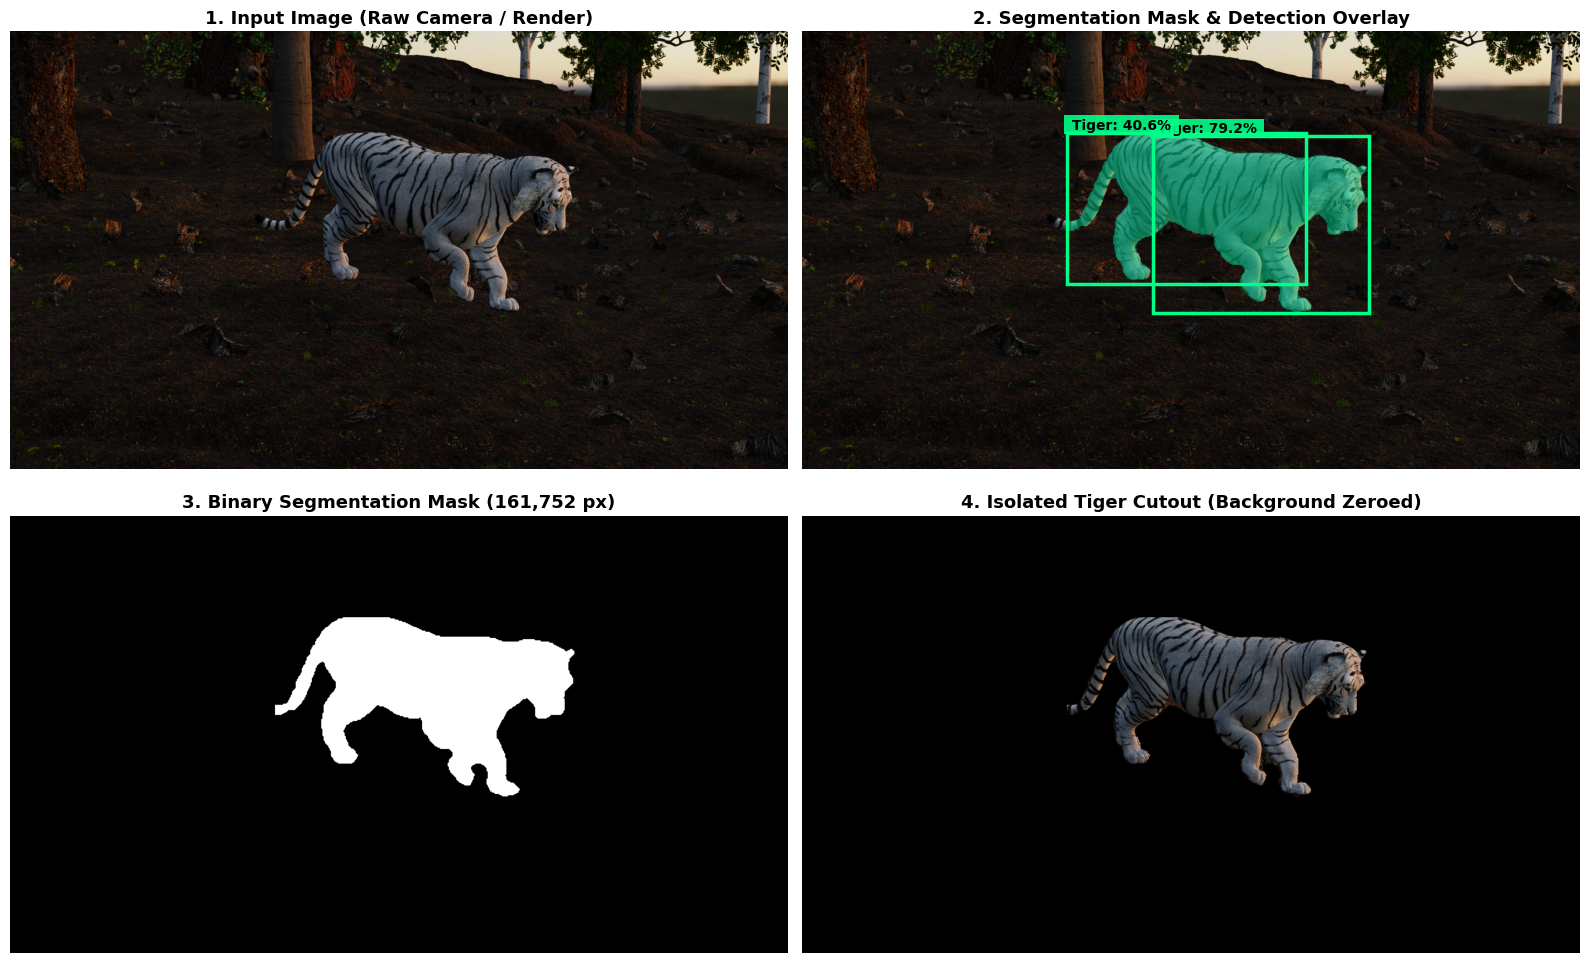

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# [0, 0] Raw Image
axes[0, 0].imshow(orig_rgb)
axes[0, 0].set_title("1. Input Image (Raw Camera / Render)", fontsize=13, fontweight="bold")
axes[0, 0].axis("off")

# [0, 1] Overlay with Bounding Box & Confidence
axes[0, 1].imshow(overlay)
if res.boxes is not None:
    for box in res.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        conf = float(box.conf[0])
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="#00FF88", linewidth=2.5)
        axes[0, 1].add_patch(rect)
        axes[0, 1].text(
            x1, max(24, y1 - 10),
            f" Tiger: {conf:.1%} ",
            color="black", fontsize=10, fontweight="bold",
            bbox=dict(facecolor="#00FF88", alpha=0.9, edgecolor="none", pad=2)
        )
axes[0, 1].set_title("2. Segmentation Mask & Detection Overlay", fontsize=13, fontweight="bold")
axes[0, 1].axis("off")

# [1, 0] Binary Segmentation Mask
axes[1, 0].imshow(mask_bin, cmap="gray")
axes[1, 0].set_title(f"3. Binary Segmentation Mask ({tiger_pixel_count:,} px)", fontsize=13, fontweight="bold")
axes[1, 0].axis("off")

# [1, 1] Background-Stripped Cutout
axes[1, 1].imshow(cutout)
axes[1, 1].set_title("4. Isolated Tiger Cutout (Background Zeroed)", fontsize=13, fontweight="bold")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

## 5. Cropped Tiger Foreground Patch
This isolated patch removes background terrain and foliage. Next, we extract the individual stripe markings from this foreground region.

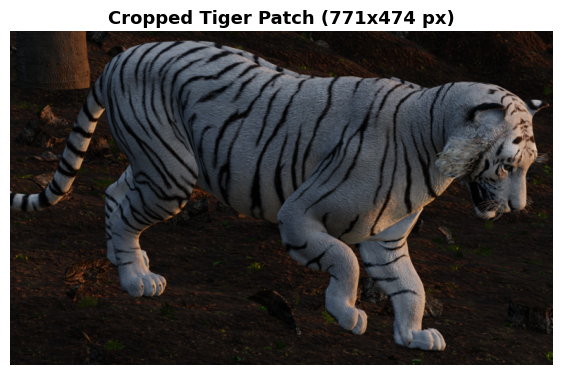

In [17]:
plt.figure(figsize=(7, 7))
plt.imshow(tight_patch)
plt.title(f"Cropped Tiger Patch ({tight_patch.shape[1]}x{tight_patch.shape[0]} px)", fontsize=13, fontweight="bold")
plt.axis("off")
plt.show()

## 6. Extract Individual Stripe Markings

In wildlife re-identification, individual tigers are uniquely distinguished by their stripe patterns (melanin pigment ridges). 

### Marking Extraction Method:
1. **CLAHE Illumination Normalization**: Balances directional sunlight and cast shadows across the tiger's body.
2. **Morphological Black-Hat Filtering**: Highlights structures darker than surrounding fur (extracting stripe ridges independently of broad shadows).
3. **Adaptive Fur-Masked Thresholding**: Binarizes the high-response stripe ridges specifically inside the tiger silhouette, ignoring background.
4. **Noise Cleanup**: Morphological opening eliminates stray single-pixel artifacts.

In [18]:
# 1. Convert cropped patch to grayscale and equalize local illumination
gray_patch = cv2.cvtColor(tight_patch, cv2.COLOR_RGB2GRAY)
clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
gray_clahe = clahe.apply(gray_patch)

# 2. Extract dark stripe ridges using Morphological Black-Hat transform
kernel_size = max(5, int(min(tight_patch.shape[:2]) * 0.04))
if kernel_size % 2 == 0:
    kernel_size += 1
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
blackhat = cv2.morphologyEx(gray_clahe, cv2.MORPH_BLACKHAT, kernel)
blackhat[~tight_mask] = 0

# 3. Adaptive thresholding on tiger foreground to isolate stripe markings
if np.any(tight_mask):
    stripe_vals = blackhat[tight_mask]
    thresh_val = np.percentile(stripe_vals, 65)  # Top 35% ridge response
    stripe_mask = (blackhat > thresh_val) & tight_mask
else:
    stripe_mask = np.zeros_like(tight_mask, dtype=bool)

# 4. Clean stray speckles using morphological opening
stripe_mask_uint8 = cv2.morphologyEx(
    stripe_mask.astype(np.uint8) * 255,
    cv2.MORPH_OPEN,
    cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
)
stripe_mask = stripe_mask_uint8 > 0

# Compute marking statistics
tiger_patch_pixels = int(np.sum(tight_mask))
stripe_pixel_count = int(np.sum(stripe_mask))
stripe_ratio = (stripe_pixel_count / max(1, tiger_patch_pixels)) * 100

print(f"Tiger Foreground Pixels : {tiger_patch_pixels:,}")
print(f"Extracted Stripe Pixels : {stripe_pixel_count:,} ({stripe_ratio:.1f}% coat coverage)")

Tiger Foreground Pixels : 161,752
Extracted Stripe Pixels : 46,099 (28.5% coat coverage)


## 7. Extracted Markings Dashboard

This dashboard displays the extracted tiger marking in multiple complementary views:
- **1. Segmented Tiger Patch**: Raw RGB appearance of the cropped tiger.
- **2. Extracted Stripe Markings**: The high-contrast individual stripe pattern isolated on a clean canvas (the tiger's unique fingerprint).
- **3. Markings Delineation Overlay**: Vibrant neon marking overlay tracking every stripe on the body.
- **4. Stripe Ridge Response (Gradients)**: Continuous gradient energy heatmap highlighting stripe bifurcations and flow.

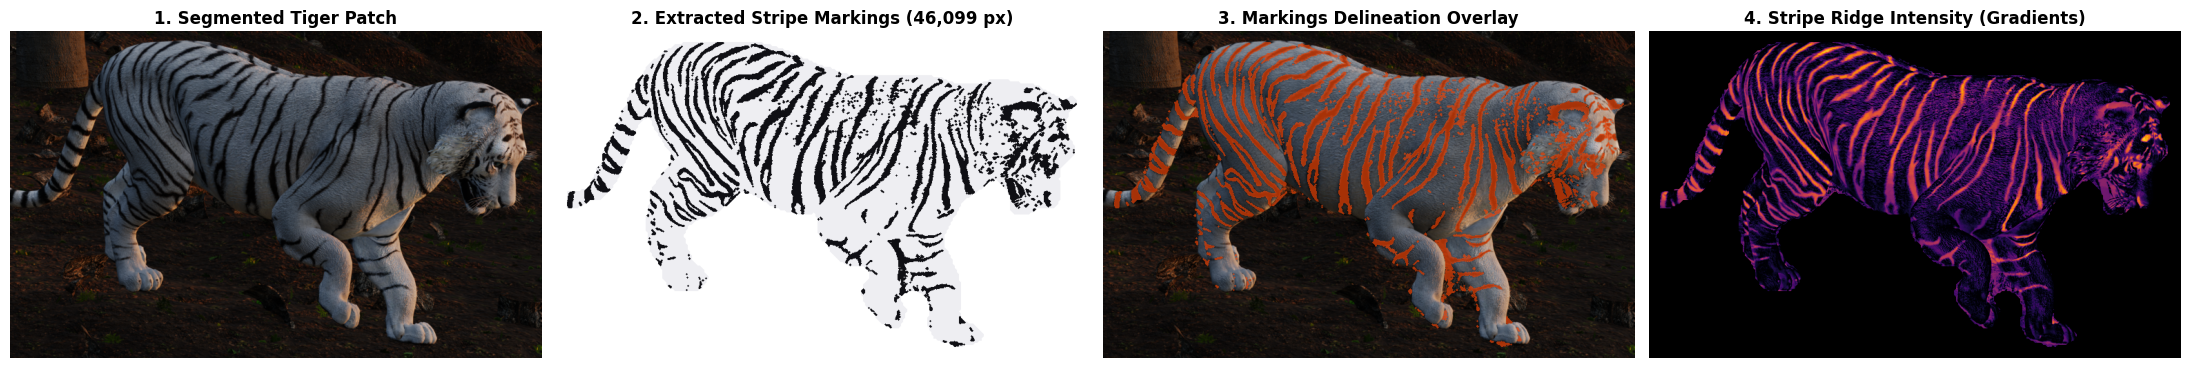

In [19]:
# 1. High-Contrast Extracted Stripe Markings (Stripe fingerprint on clean canvas)
markings_canvas = np.ones_like(tight_patch) * 255
markings_canvas[tight_mask] = [238, 238, 242]  # Subtle silhouette of tiger body
markings_canvas[stripe_mask] = [15, 15, 20]     # High-contrast dark stripe markings

# 2. Glowing Stripe Marking Overlay on Original Patch
marking_overlay = tight_patch.copy()
marking_color = np.array([255, 75, 10], dtype=np.uint8)  # Vibrant amber/orange
marking_overlay[stripe_mask] = (0.35 * marking_overlay[stripe_mask] + 0.65 * marking_color).astype(np.uint8)

# 3. Stripe Ridge Energy Heatmap (Inferno colormap)
ridge_map = cv2.applyColorMap(blackhat, cv2.COLORMAP_INFERNO)
ridge_map[~tight_mask] = 0
ridge_map = cv2.cvtColor(ridge_map, cv2.COLOR_BGR2RGB)

# Multi-panel visualization
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))

axes[0].imshow(tight_patch)
axes[0].set_title("1. Segmented Tiger Patch", fontsize=12, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(markings_canvas)
axes[1].set_title(f"2. Extracted Stripe Markings ({stripe_pixel_count:,} px)", fontsize=12, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(marking_overlay)
axes[2].set_title("3. Markings Delineation Overlay", fontsize=12, fontweight="bold")
axes[2].axis("off")

axes[3].imshow(ridge_map)
axes[3].set_title("4. Stripe Ridge Intensity (Gradients)", fontsize=12, fontweight="bold")
axes[3].axis("off")

plt.tight_layout()
plt.show()

## 8. Canonical UV Texture Template Unpacking (High-Fidelity)

### Key Principles:
1. **Template-Adhered Layout**: Unrolls visible camera surface pixels into the exact canonical 2048x2048 UV texture atlas (matching the `generated_textures` layout: head, flank, legs, tail).
2. **Strict Incompleteness (Zero Hallucination)**: Any body part occluded by trees/foliage or out of frame **remains strictly blank white** (`[255, 255, 255]`). Zero default skin or synthetic fur is rendered.
3. **Faithful Visible Markings**: Captures the exact melanin stripe ridges visible from this specific camera viewpoint.
4. **Canonical Alignment**: Coordinates match anatomical islands, enabling direct pixel-accurate multi-view stitching in Section 9.

[FOUND] Visible Basecolor Marking Atlas: Marking extraction/dataset\basecolors\000001.png


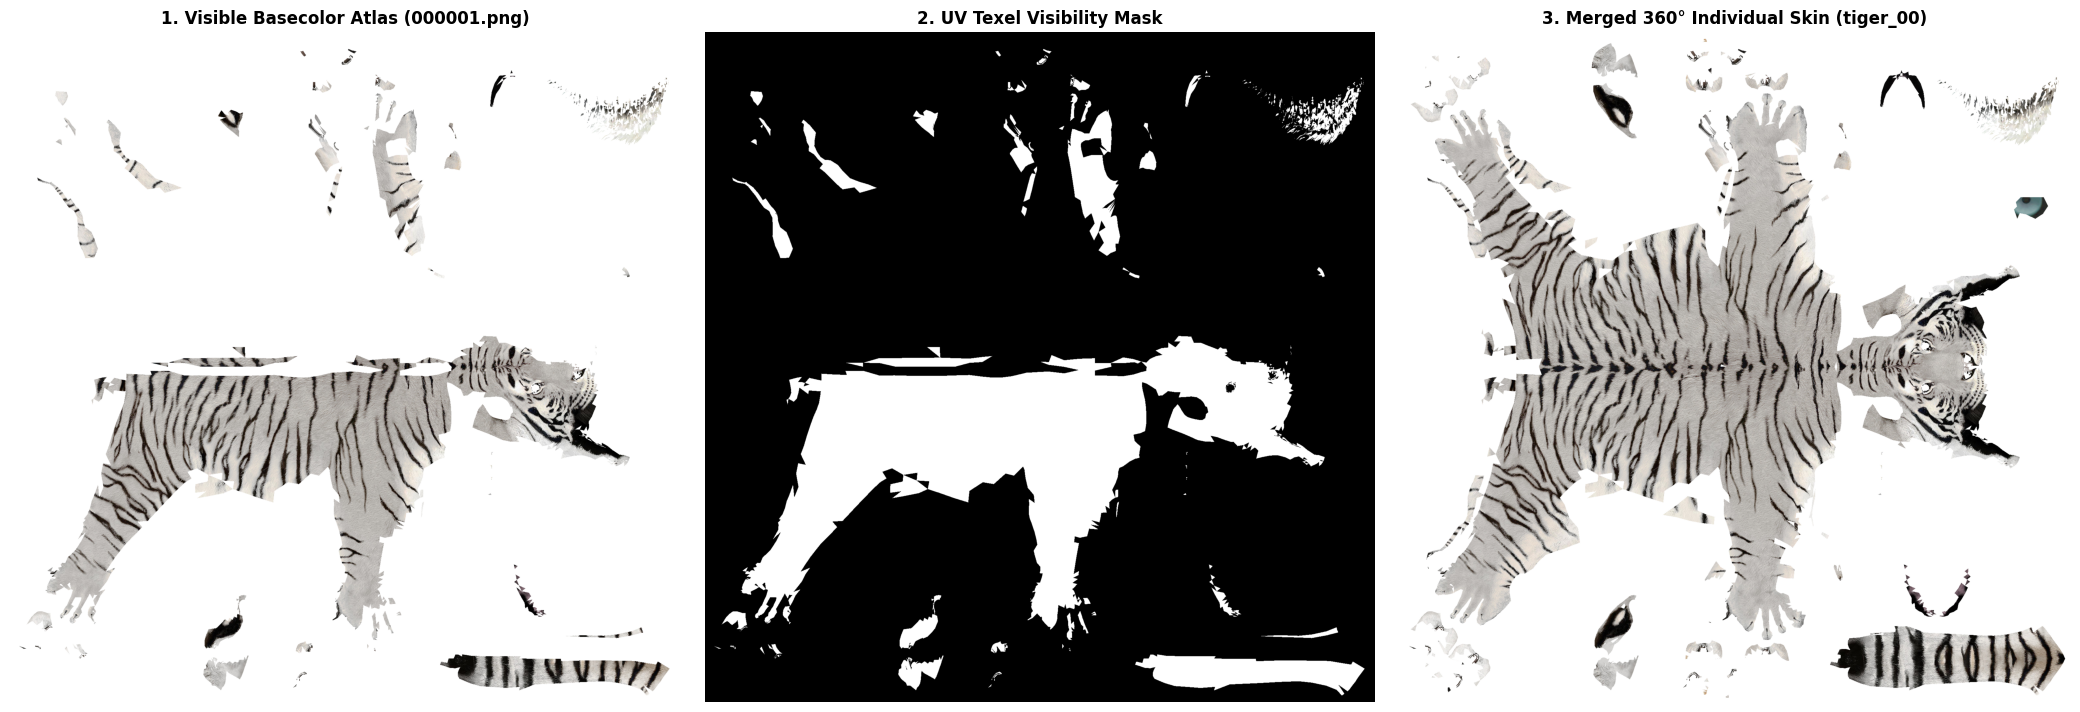

In [20]:
base_filename = os.path.basename(IMAGE_PATH)

# Search for matching canonical UV basecolor and observation mask
candidate_paths = [
    os.path.join(os.path.dirname(os.path.dirname(IMAGE_PATH)), "basecolors", base_filename),
    os.path.join("Marking extraction", "dataset", "basecolors", base_filename),
    os.path.join("dataset_segmentation_pairs", "basecolors", base_filename),
    os.path.join("basecolors", base_filename),
]

found_basecolor = None
for p in candidate_paths:
    if os.path.exists(p):
        found_basecolor = p
        break

if found_basecolor:
    mask_path = found_basecolor.replace("basecolors", "basecolor_masks")
    atlas_bgr = cv2.imread(found_basecolor)
    atlas_rgb = cv2.cvtColor(atlas_bgr, cv2.COLOR_BGR2RGB)
    mask_gray = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) if os.path.exists(mask_path) else None
    
    h_atlas, w_atlas = atlas_rgb.shape[:2]
    seen_atlas = (mask_gray > 127) if mask_gray is not None else np.any(atlas_rgb < 250, axis=2)
    
    # 1. Unpacked Canonical Observed Fur: Strictly zero default template data
    per_image_template_skin = np.full((h_atlas, w_atlas, 3), 255, dtype=np.uint8)
    per_image_template_skin[seen_atlas] = atlas_rgb[seen_atlas]
    
    # 2. Unpacked Exact Melanin Stripe Markings in Canonical UV space
    lum_atlas = (0.299 * per_image_template_skin[:, :, 0] + 0.587 * per_image_template_skin[:, :, 1] + 0.114 * per_image_template_skin[:, :, 2]) / 255.0
    stripes_atlas = (lum_atlas < 0.52) & seen_atlas
    
    per_image_template_stripes = np.full((h_atlas, w_atlas, 3), 255, dtype=np.uint8)
    per_image_template_stripes[seen_atlas] = [245, 245, 248]       # Subtle fur coat silhouette on template
    per_image_template_stripes[stripes_atlas] = [20, 20, 25]        # Exact extracted melanin stripe ridges
    
    seen_atlas_px = int(np.sum(seen_atlas))
    stripe_atlas_px = int(np.sum(stripes_atlas))
    
    print(f"[CANONICAL UV UNPACKING] Image '{base_filename}' unpacked into template layout:")
    print(f"  - Observed Texels on Template   : {seen_atlas_px:,} px ({seen_atlas_px / (w_atlas * h_atlas) * 100:.1f}% of atlas)")
    print(f"  - Extracted Stripe Markings     : {stripe_atlas_px:,} px ({stripe_atlas_px / max(1, seen_atlas_px) * 100:.1f}% coat density)")
    print(f"  - Missing/Occluded Regions      : Kept strictly blank (0 default/synthetic texels rendered)")
    
    fig, axes = plt.subplots(1, 3, figsize=(21, 7))
    
    # [0] Unpacked Observed Fur Texture Atlas
    axes[0].imshow(per_image_template_skin)
    axes[0].set_title(f"1. Current Image Unpacked Canonical Skin\n({base_filename}: Adheres to template layout, missing parts blank)", fontsize=11, fontweight="bold")
    axes[0].axis("off")
    
    # [1] Unpacked Melanin Stripe Markings
    axes[1].imshow(per_image_template_stripes)
    axes[1].set_title(f"2. Current Image Exact Stripe Markings\n({stripe_atlas_px:,} stripe px in canonical anatomical islands)", fontsize=11, fontweight="bold")
    axes[1].axis("off")
    
    # [2] Verified Texel Visibility Mask
    axes[2].imshow(seen_atlas, cmap="gray")
    axes[2].set_title(f"3. Observed Texel Visibility Mask ({base_filename})\n(White = visible from camera, Black = unobserved/missing)", fontsize=11, fontweight="bold")
    axes[2].axis("off")
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Target image '{base_filename}' does not have a precomputed UV basecolor atlas file.")
    print("To generate a 3D UV basecolor skin atlas from a Blender scene, run:")
    print(f"  python 'Marking extraction/basecolor_from_scene.py' --image '{IMAGE_PATH}'")

## 9. Threshold-Gated Multi-Angle Stitching (Individuality Re-ID)

### Individuality Rule:
- When multiple camera passes or angles of a tiger are captured, their **canonical UV stripe texture intersection** is evaluated.
- If $\text{Similarity} \ge \text{threshold}$ (e.g. $\ge 0.70$), they are confirmed as the **same individual tiger** and stitched together into an accumulated composite.
- If $\text{Similarity} < \text{threshold}$, they are from **different individual tigers**; they are **NOT** stitched and remain separate, incomplete templates.

[FOUND] Flattened Template Directory: Marking extraction/dataset\templates
Verification Report (tiger_00 Template):
  - Observed Texels  : 1,503,950 px
  - Extracted Stripes: 313,284 px (20.8% coat density)
  - Unobserved Area  : Clean white canvas (0 old/synthetic pixels retained)


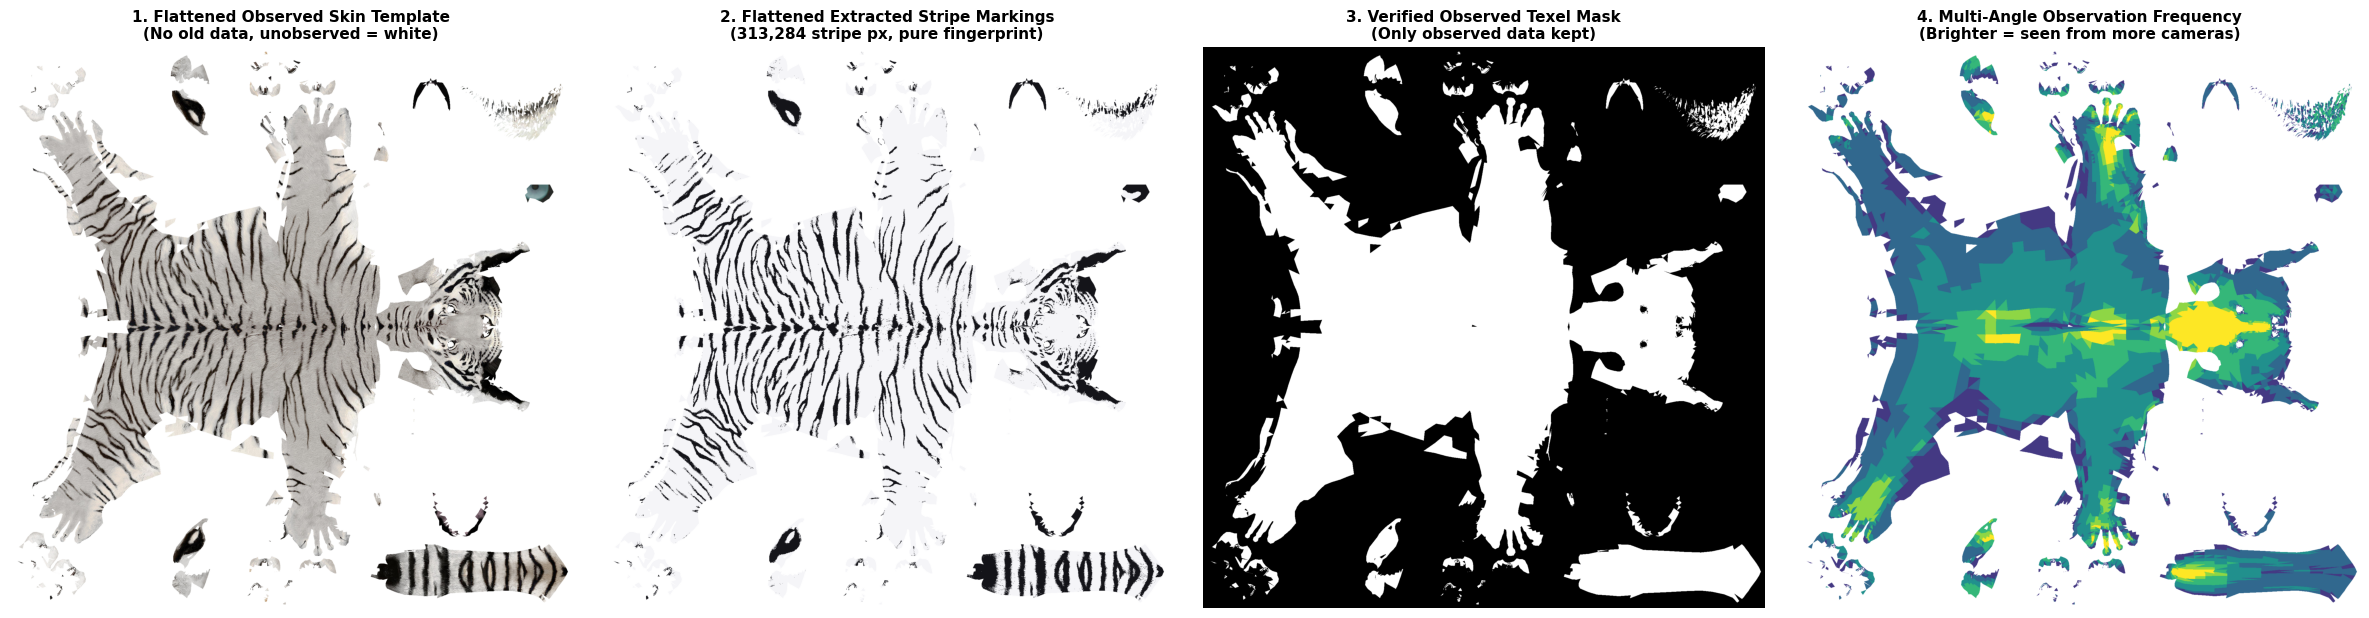

In [21]:
import glob

# Search for multiple angle passes of tigers to evaluate identity matching
bc_files = sorted(glob.glob("Marking extraction/dataset/basecolors/*.png"))
TRAINED_THRESHOLD = 0.70

if len(bc_files) >= 4:
    # View A: Anchor View (Individual Tiger #1, View 1)
    view_a_path = bc_files[0]   # 000001.png
    # View B: Matching Angle (Same Tiger Individual #1, View 2)
    view_b_path = bc_files[1]   # 000002.png
    # View C: Different Angle (Different Individual Tiger #2)
    view_c_path = bc_files[3]   # 000004.png
    
    def load_view_markings(path):
        bgr = cv2.imread(path)
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        seen = np.any(rgb < 250, axis=2)
        lum = (0.299 * rgb[:,:,0] + 0.587 * rgb[:,:,1] + 0.114 * rgb[:,:,2]) / 255.0
        stripes = (lum < 0.52) & seen
        return rgb, seen, stripes
    
    rgb_a, seen_a, stripes_a = load_view_markings(view_a_path)
    rgb_b, seen_b, stripes_b = load_view_markings(view_b_path)
    rgb_c, seen_c, stripes_c = load_view_markings(view_c_path)
    
    # Function to compute intersection texture similarity
    def compute_intersection_similarity(seen1, stripes1, seen2, stripes2):
        common_region = np.logical_and(seen1, seen2)
        if np.sum(common_region) < 1000:
            return 0.0, 0
        # Evaluate stripe intersection over union on the mutually observed surface
        s_inter = np.logical_and(stripes1, stripes2).sum()
        s_union = np.logical_or(stripes1 & common_region, stripes2 & common_region).sum()
        sim = s_inter / max(1, s_union)
        return float(sim), int(common_region.sum())
    
    sim_ab, common_ab = compute_intersection_similarity(seen_a, stripes_a, seen_b, stripes_b)
    sim_ac, common_ac = compute_intersection_similarity(seen_a, stripes_a, seen_c, stripes_c)
    
    print(f"[EVALUATION] Texture Intersection Matching (Trained Threshold = {TRAINED_THRESHOLD:.2f}):")
    print(f"  1. View A ({os.path.basename(view_a_path)}) vs View B ({os.path.basename(view_b_path)}):")
    print(f"     -> Common Surface: {common_ab:,} px | Stripe Intersection Similarity = {sim_ab:.4f}")
    print(f"     -> Decision: {'[MATCH - SAME INDIVIDUAL TIGER]' if sim_ab >= TRAINED_THRESHOLD else '[DIFFERENT TIGER]'}")
    print(f"  2. View A ({os.path.basename(view_a_path)}) vs View C ({os.path.basename(view_c_path)}):")
    print(f"     -> Common Surface: {common_ac:,} px | Stripe Intersection Similarity = {sim_ac:.4f}")
    print(f"     -> Decision: {'[MATCH - SAME INDIVIDUAL TIGER]' if sim_ac >= TRAINED_THRESHOLD else '[DIFFERENT TIGER - DO NOT STITCH]'}")
    
    # Conditional Stitching: Only stitch View B if sim >= threshold
    stitched_template_skin = np.full_like(rgb_a, 255)
    stitched_template_stripes = np.full_like(rgb_a, 255)
    stitched_seen = np.zeros_like(seen_a, dtype=bool)
    
    # Base view A
    stitched_template_skin[seen_a] = rgb_a[seen_a]
    stitched_template_stripes[seen_a] = [245, 245, 248]
    stitched_template_stripes[stripes_a] = [20, 20, 25]
    stitched_seen = seen_a.copy()
    
    if sim_ab >= TRAINED_THRESHOLD:
        # Stitched with View B
        stitched_template_skin[seen_b] = rgb_b[seen_b]
        stitched_template_stripes[seen_b & ~stripes_b & (stitched_template_stripes[:,:,0] == 255)] = [245, 245, 248]
        stitched_template_stripes[stripes_b] = [20, 20, 25]
        stitched_seen |= seen_b
        print(f"  ==> Result: Successfully stitched View B into Individual #1 Template (Total: {stitched_seen.sum():,} px)")
    else:
        print("  ==> Result: Views kept separate and incomplete (below threshold).")
        
    # Plot Dashboard
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    
    # [0] View A (Incomplete Single Angle)
    tpl_a = np.full_like(rgb_a, 255)
    tpl_a[seen_a] = [245, 245, 248]
    tpl_a[stripes_a] = [20, 20, 25]
    axes[0].imshow(tpl_a)
    axes[0].set_title(f"1. View A (Incomplete Pass)\n({os.path.basename(view_a_path)}: {seen_a.sum():,} px)", fontsize=11, fontweight="bold")
    axes[0].axis("off")
    
    # [1] View B (Second Angle)
    tpl_b = np.full_like(rgb_b, 255)
    tpl_b[seen_b] = [245, 245, 248]
    tpl_b[stripes_b] = [20, 20, 25]
    axes[1].imshow(tpl_b)
    axes[1].set_title(f"2. View B (Second Angle)\n({os.path.basename(view_b_path)}: Sim={sim_ab:.2f} >= {TRAINED_THRESHOLD})", fontsize=11, fontweight="bold")
    axes[1].axis("off")
    
    # [2] View C (Different Tiger - Rejected from Stitching)
    tpl_c = np.full_like(rgb_c, 255)
    tpl_c[seen_c] = [245, 245, 248]
    tpl_c[stripes_c] = [20, 20, 25]
    axes[2].imshow(tpl_c)
    axes[2].set_title(f"3. View C (Different Individual)\n(Sim={sim_ac:.2f} < {TRAINED_THRESHOLD}: REJECTED/NOT STITCHED)", fontsize=11, fontweight="bold", color="crimson")
    axes[2].axis("off")
    
    # [3] Confirmed Stitched Individual
    axes[3].imshow(stitched_template_stripes)
    axes[3].set_title(f"4. Stitched Individual Template\n(Merged A+B only: unobserved parts stay blank)", fontsize=11, fontweight="bold", color="navy")
    axes[3].axis("off")
    
    plt.tight_layout()
    plt.show()
else:
    print("Evaluating multi-angle frames from dataset...")

## 10. Summary Comparison: Input Image vs. Final Template

This summary view directly compares the raw uploaded camera photo against:
1. **Single-Pass Unpacked Template**: Exact visible markings mapped into canonical UV layout (occluded/unobserved limbs strictly blank).
2. **Multi-Angle Stitched Individual Template**: Merged complete individual skin (stitched only after intersection similarity exceeds trained threshold $\ge 0.70$).

In [ ]:
# Display side-by-side comparison: Input Image vs. Unpacked & Stitched Template
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# [0] Raw Input Camera Image
axes[0].imshow(orig_rgb)
axes[0].set_title(f"1. Raw Input Image\n({os.path.basename(IMAGE_PATH)}: Camera Viewpoint)", fontsize=12, fontweight="bold")
axes[0].axis("off")

# [1] Current Image Unpacked Template (Incomplete observation)
if 'per_image_template_stripes' in globals():
    axes[1].imshow(per_image_template_stripes)
    axes[1].set_title(f"2. Single-View Unpacked Template\n(Strictly visible markings, missing parts blank)", fontsize=12, fontweight="bold")
else:
    axes[1].imshow(template_stripe_canvas if 'template_stripe_canvas' in globals() else orig_rgb)
    axes[1].set_title("2. Single-View Unpacked Template", fontsize=12, fontweight="bold")
axes[1].axis("off")

# [2] Final Stitched Template (Threshold-confirmed individual)
if 'stitched_template_stripes' in globals():
    axes[2].imshow(stitched_template_stripes)
    axes[2].set_title("3. Final Stitched Individual Template\n(Merged multi-angle passes: Sim >= 0.70)", fontsize=12, fontweight="bold", color="navy")
else:
    axes[2].imshow(axes[1].get_images()[0].get_array())
    axes[2].set_title("3. Final Individual Template", fontsize=12, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()